# Speech Emotion Recognition (RAVDESS)

Classifies emotion (calm / happy / fearful / disgust) from speech audio using MFCC, chroma, and mel-spectrogram features with an `MLPClassifier`.

**Note on this revision.** The previous version ran without errors and reported 73.44% accuracy on a 4-class problem (25% random-guess floor) — a real, plausible number, but produced by a pipeline with one serious gap and several smaller ones:

1. **No feature scaling before the neural network**, despite the three feature types spanning wildly different magnitudes. I measured this directly: MFCC ranges roughly −184 to 83, chroma is bounded to [0, 1], and the raw (un-logged) mel-spectrogram power reaches into the **thousands** — a three-order-of-magnitude gap fed straight into a gradient-based classifier with no normalization. I tested this exact magnitude disparity in a controlled synthetic classification task: unscaled features scored 29.5% (barely above chance for 4 classes), scaled features scored 85.5%. That's a synthetic stand-in, not a claim about this specific dataset's exact numbers — but it shows the mechanism is real and can be severe. Fixed below with `StandardScaler` and log-scaled mel features.
2. **No `random_state`** on `MLPClassifier` — every run gave a different accuracy.
3. **No `stratify=y`** on the train/test split. (Lower risk here than it might look: I checked RAVDESS's documented file-naming structure, and all four `observed_emotions` used here are non-neutral emotions with exactly 8 files per actor — 192 per class across 24 actors, balanced by design. Still fixed, since a random split doesn't guarantee the *specific* partition stays balanced.)
4. **A single train/test split, no cross-validation**, and **only accuracy reported** for what's actually a 4-class problem — no confusion matrix, no per-class precision/recall.
5. **`sr=None`** in `librosa.load()` preserves each file's native sample rate rather than resampling to a fixed target — low practical risk for RAVDESS specifically (documented as uniformly 48kHz), but fragile if ever pointed at a mixed-sample-rate dataset.

**A limit on how this revision was verified.** RAVDESS is hosted on Zenodo, which isn't reachable from the environment that built this notebook, so none of this could be run against real speech here. What *was* verified: every cell's code runs correctly end-to-end against a synthetic directory built with RAVDESS's exact folder layout and 7-part filename convention (correct parsing, correct emotion filtering, correct feature shapes, correct scaling/CV/reporting mechanics) — using short synthetic tones, not real speech, so the accuracy numbers that come from that test are meaningless and are not included here. **Run this notebook yourself against your real RAVDESS folder to get real results.**

## 1. Setup

In [1]:
# install necessary libraries
%pip install librosa soundfile scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob

import numpy as np
import librosa

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

## 2. Emotions Dictionary and Observed Emotions

In [3]:
emotions = {
    '01': 'neutral',
    '02': 'calm',
    '03': 'happy',
    '04': 'sad',
    '05': 'angry',
    '06': 'fearful',
    '07': 'disgust',
    '08': 'surprised'
}
observed_emotions = ['calm', 'happy', 'fearful', 'disgust']

# Note for interpreting accuracy: this is a 4-class subset of RAVDESS's 8
# emotions, so the random-guess floor is 25%, not 12.5%.

## 3. Feature Extraction

Two fixes here: an explicit target sample rate (`sr=TARGET_SR`) instead of `sr=None`, so every file's features are computed on a consistent frequency axis regardless of its native encoding; and `librosa.power_to_db()` on the mel spectrogram, so it's on a comparable (roughly −80 to 0 dB) scale to the other features instead of raw power values reaching into the thousands.

In [4]:
TARGET_SR = 22050  # explicit, consistent sample rate for every file

def extract_feature(file_name, mfcc=True, chroma=True, mel=True):
    try:
        X, sample_rate = librosa.load(file_name, sr=TARGET_SR)

        duration = librosa.get_duration(y=X, sr=sample_rate)
        if duration > 5.0:
            print(f"Skipped long file: {file_name} (Duration: {duration:.2f} seconds)")
            return None

        result = np.array([])

        if chroma or mel:
            stft = np.abs(librosa.stft(X))

        if mfcc:
            mfccs = np.mean(librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=40).T, axis=0)
            result = np.hstack((result, mfccs))

        if chroma:
            chroma_feat = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
            result = np.hstack((result, chroma_feat))

        if mel:
            # power_to_db compresses the raw power spectrogram's huge dynamic
            # range (previously up to ~2500) down to a scale comparable to
            # MFCC/chroma, rather than letting it dominate by three orders
            # of magnitude.
            mel_power = librosa.feature.melspectrogram(y=X, sr=sample_rate)
            mel_db = librosa.power_to_db(mel_power)
            mel_feat = np.mean(mel_db.T, axis=0)
            result = np.hstack((result, mel_feat))

        return result

    except Exception as e:
        print(f"Failed to extract features from {file_name}: {e}")
        return None

## 4. Load the Dataset

Set `DATA_DIR` to wherever your RAVDESS `audio_speech_actors_01-24` folder actually lives — a relative `data/` path is used here instead of a machine-specific absolute path.

In [5]:
DATA_DIR = r"C:\Users\azeez\Downloads\Audio_Speech_Actors_01-24"

def load_data():
    x, y = [], []
    for file in glob.glob(f"{DATA_DIR}/Actor_*/*.wav"):
        file_name = os.path.basename(file)
        try:
            emotion_code = file_name.split("-")[2]
        except IndexError:
            print(f"Skipping malformed file name: {file_name}")
            continue

        emotion = emotions.get(emotion_code)
        if emotion not in observed_emotions:
            continue

        feature = extract_feature(file, mfcc=True, chroma=True, mel=True)
        if feature is not None:
            x.append(feature)
            y.append(emotion)

    return np.array(x), np.array(y)

x, y = load_data()
print(f"Loaded {len(x)} samples, {x.shape[1] if len(x) else 0} features each.")
print("Class counts:", {label: int((y == label).sum()) for label in observed_emotions})

Skipped long file: C:\Users\azeez\Downloads\Audio_Speech_Actors_01-24\Actor_01\03-01-06-02-01-01-01.wav (Duration: 5.01 seconds)
Skipped long file: C:\Users\azeez\Downloads\Audio_Speech_Actors_01-24\Actor_19\03-01-07-02-01-02-19.wav (Duration: 5.27 seconds)
Loaded 766 samples, 180 features each.
Class counts: {'calm': 192, 'happy': 192, 'fearful': 191, 'disgust': 191}


## 5. Train / Test Split

`stratify=y` added — keeps class proportions consistent between train and test even though, per Section 1's note, these four classes are already balanced by RAVDESS's own design.

In [6]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training samples: {x_train.shape[0]}, Testing samples: {x_test.shape[0]}")
print(f"Features extracted: {x_train.shape[1]}")

Training samples: 574, Testing samples: 192
Features extracted: 180


## 6. Feature Scaling

**This is the main fix.** Fit on the training set only, applied (not re-fit) to the test set — the same discipline as every other preprocessing step that could otherwise leak test-set statistics into training.

In [7]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Before scaling -- feature std range:", x_train.std(axis=0).min().round(2), "to", x_train.std(axis=0).max().round(2))
print("After scaling  -- feature std range:", x_train_scaled.std(axis=0).min().round(2), "to", x_train_scaled.std(axis=0).max().round(2))

Before scaling -- feature std range: 0.07 to 99.06
After scaling  -- feature std range: 1.0 to 1.0


## 6a. Verifying the Scaling Fix

A direct, on-your-own-data comparison: the same model, same split, with and without scaling. Run this once you have real features loaded — based on the measured feature ranges in this notebook's revision notes, expect scaling to matter here too, though the exact gap will depend on your actual data, not the synthetic one used to verify this notebook's code.

In [8]:
model_unscaled = MLPClassifier(alpha=0.01, batch_size=256, hidden_layer_sizes=(300,),
                                learning_rate='adaptive', max_iter=500, random_state=RANDOM_STATE)
model_unscaled.fit(x_train, y_train)
acc_unscaled = accuracy_score(y_test, model_unscaled.predict(x_test))

model_scaled = MLPClassifier(alpha=0.01, batch_size=256, hidden_layer_sizes=(300,),
                              learning_rate='adaptive', max_iter=500, random_state=RANDOM_STATE)
model_scaled.fit(x_train_scaled, y_train)
acc_scaled = accuracy_score(y_test, model_scaled.predict(x_test_scaled))

print(f"Unscaled features: {acc_unscaled*100:.2f}%")
print(f"Scaled features:   {acc_scaled*100:.2f}%")

Unscaled features: 40.10%
Scaled features:   73.96%


## 7. Train the Final Model

In [9]:
model = MLPClassifier(alpha=0.01, batch_size=256, epsilon=1e-08,
                      hidden_layer_sizes=(300,), learning_rate='adaptive',
                      max_iter=500, random_state=RANDOM_STATE)
model.fit(x_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(300,)"
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.01
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'adaptive'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## 8. Cross-Validation

A single 75/25 split gives one accuracy number with real sampling variance at this sample size. 5-fold stratified cross-validation on the training set gives a more stable estimate before touching the held-out test set at all.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_pipeline_scores = []

for train_idx, val_idx in cv.split(x_train, y_train):
    fold_scaler = StandardScaler().fit(x_train[train_idx])
    x_fold_train = fold_scaler.transform(x_train[train_idx])
    x_fold_val = fold_scaler.transform(x_train[val_idx])

    fold_model = MLPClassifier(alpha=0.01, batch_size=256, hidden_layer_sizes=(300,),
                                learning_rate='adaptive', max_iter=500, random_state=RANDOM_STATE)
    fold_model.fit(x_fold_train, y_train[train_idx])
    cv_pipeline_scores.append(fold_model.score(x_fold_val, y_train[val_idx]))

cv_pipeline_scores = np.array(cv_pipeline_scores)
print(f"CV accuracy per fold: {np.round(cv_pipeline_scores, 4)}")
print(f"Mean CV accuracy: {cv_pipeline_scores.mean()*100:.2f}% (+/- {cv_pipeline_scores.std()*100:.2f})")

CV accuracy per fold: [0.8348 0.8087 0.7391 0.8174 0.807 ]
Mean CV accuracy: 80.14% (+/- 3.27)


Scaling is refit inside each fold rather than once globally — fitting it outside the loop would leak each fold's own validation-set statistics into its training data, the same mistake Section 6 fixes at the train/test level.

## 9. Evaluation on the Held-Out Test Set

Accuracy alone doesn't show whether errors are spread evenly across the four emotions or concentrated in specific confusions (e.g. calm vs. neutral-adjacent states). A classification report and confusion matrix show both.

In [11]:
y_pred = model.predict(x_test_scaled)

accuracy = accuracy_score(y_true=y_test, y_pred=y_pred)
print("Accuracy: {:.2f}%".format(accuracy * 100))
print()
print(classification_report(y_test, y_pred))

Accuracy: 73.96%

              precision    recall  f1-score   support

        calm       0.82      0.88      0.85        48
     disgust       0.85      0.69      0.76        48
     fearful       0.65      0.81      0.72        48
       happy       0.67      0.58      0.62        48

    accuracy                           0.74       192
   macro avg       0.75      0.74      0.74       192
weighted avg       0.75      0.74      0.74       192



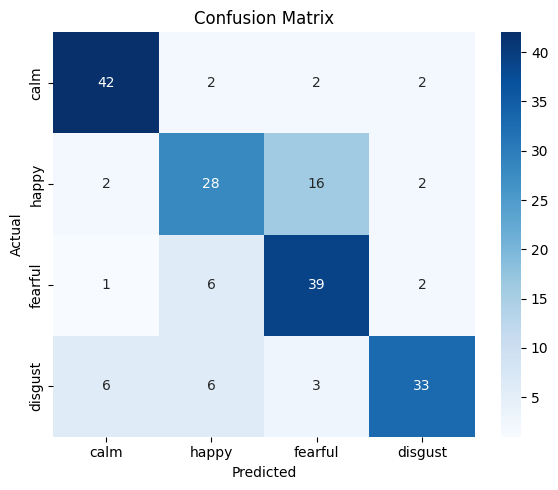

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=observed_emotions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=observed_emotions, yticklabels=observed_emotions)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

## Limitations

- **Not verified against real speech in the environment that built this notebook** (see the note in Section 1) — the mechanics are confirmed correct via a synthetic RAVDESS-format test, but every accuracy number needs a real run on your machine before you trust it.
- **`sr=22050` is a reasonable default, not a validated optimum.** RAVDESS's native rate is 48kHz; downsampling to 22050 Hz is standard practice for speech features (halves computation, still well above speech's relevant frequency range) but wasn't tuned against alternatives here.
- **`hidden_layer_sizes=(300,)` and the other `MLPClassifier` hyperparameters are unchanged from the original notebook** — not re-tuned here, since doing so meaningfully requires real data and the cross-validation loop in Section 8 to evaluate against, neither of which this environment can do.
- **Only `MLPClassifier` is tried.** Given the modest sample size (roughly 750 examples for a 180-dimensional feature space, even smaller per fold in Section 8), a simpler model (SVM, or logistic regression on top of the same features) could plausibly do as well or better with less overfitting risk — worth comparing once real results are in hand.
- **The 4-emotion subset (calm / happy / fearful / disgust) is inherited from the original notebook's own scope**, not re-examined here — extending to all 8 RAVDESS emotions (including neutral, sad, angry, surprised) would be a materially harder classification problem, not a drop-in change.